# 01 — EDA del MVP · Humo en la temporada

Primera mirada punta a punta: focos reales de FIRMS y alojamientos reales de Booking, unidos por distancia.

**Qué es verificado y qué es supuesto**
- *Verificado (datos reales, 06–07/11/2026):* focos VIIRS S-NPP (procesamiento estándar) de dic–mar de
  ambas temporadas; 459 alojamientos de Booking; 2.062 reviews de una muestra de 37 alojamientos.
- *Decisión del grupo (07/11):* la distancia se mide solo a eventos FIRMS con ≥50 detecciones.
- *Limitación:* la muestra de reviews es chica (al azar dentro de la zona a ≤40 km del fuego + 9 de
  Bariloche) y se excluyen del panel los alojamientos con historia truncada por fallas del actor.
- *Supuesto:* el volumen de reviews por mes de estadía es proxy de ocupación.

Entradas: `data/processed/` (generado por `firms_backfill.py`, `src/build_panel.py`, `src/did_baseline.py`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

P = "../data/processed"
focos = pd.read_csv(f"{P}/firms_celda_dia.csv", parse_dates=["acq_date"])
aloj = pd.read_csv(f"{P}/alojamientos.csv")
panel = pd.read_csv(f"{P}/panel_stacked.csv", dtype={"temporada": str})
did = pd.read_csv(f"{P}/did_baseline.csv", dtype={"temporada": str})
focos["temporada"] = np.where(focos["acq_date"] >= "2025-06-01", "2026", "2025")

# Estilo: superficie clara, tinta neutra, grilla recesiva, marcas finas.
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
FUEGO = "#eb6834"                      # focos (slot categórico 2)
BANDAS = ["0-15", "15-40", "40-80", ">80"]
AZUL = dict(zip(BANDAS, ["#104281", "#256abf", "#5598e7", "#86b6ef"]))  # ordinal: más oscuro = más cerca
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False, "axes.axisbelow": True,
})
print(f"focos (celda × día): {len(focos)} | alojamientos: {len(aloj)} | panel apilado: {len(panel)} filas")

focos (celda × día): 1669 | alojamientos: 459 | panel apilado: 263 filas


## 1. Mapa de focos y alojamientos por banda de distancia

Un panel por temporada: celdas que ardieron (naranja, tamaño ∝ FRP) y alojamientos coloreados por la banda
de distancia al foco más cercano de **esa** temporada. Proyección equirectangular corregida por la latitud media.

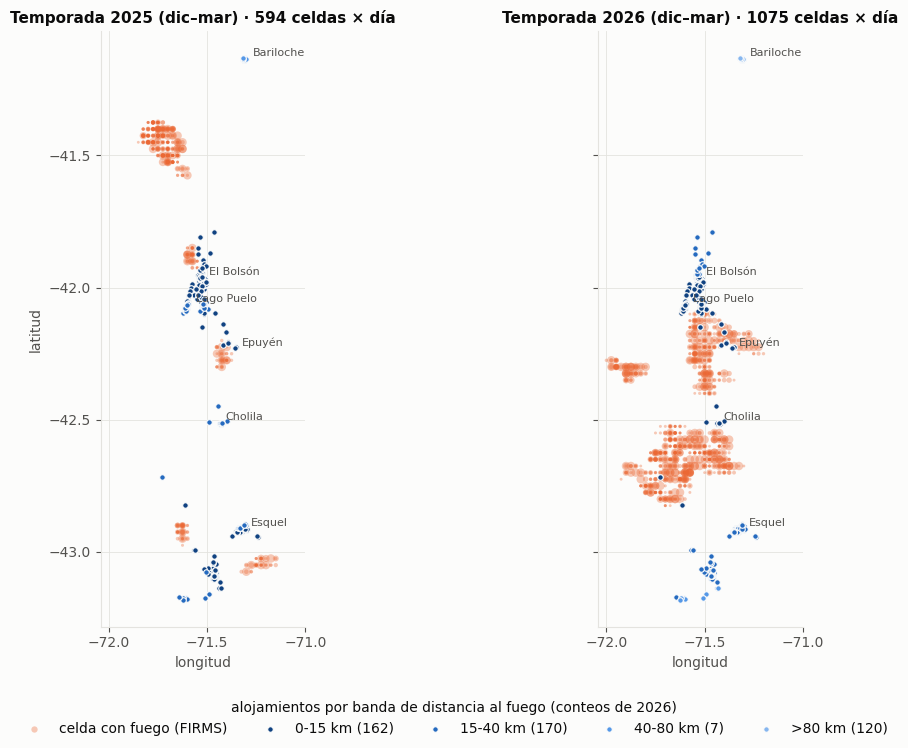

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, temp in zip(axes, ["2025", "2026"]):
    f = focos[focos["temporada"] == temp]
    ax.scatter(f["celda_lon"], f["celda_lat"], s=4 + f["frp_total_mw"].clip(upper=400) / 12,
               color=FUEGO, alpha=0.35, linewidths=0, label="celda con fuego (FIRMS)")
    for b in BANDAS:
        a = aloj[aloj[f"banda_{temp}"] == b]
        ax.scatter(a["lng"], a["lat"], s=16, color=AZUL[b], edgecolors=SURF, linewidths=0.8,
                   label=f"{b} km ({len(a)})", zorder=3)
    for loc, (la, ln) in {"Bariloche": (-41.133, -71.310), "El Bolsón": (-41.964, -71.534),
                          "Lago Puelo": (-42.066, -71.600), "Epuyén": (-42.231, -71.367),
                          "Cholila": (-42.513, -71.447), "Esquel": (-42.911, -71.319)}.items():
        ax.annotate(loc, (ln, la), xytext=(6, 2), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_title(f"Temporada {temp} (dic–mar) · {len(f)} celdas × día")
    ax.set_aspect(1 / np.cos(np.deg2rad(-42)))
    ax.set_xticks([-72.0, -71.5, -71.0])
    ax.set_xlabel("longitud")
axes[0].set_ylabel("latitud")
h, l = axes[1].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, title="alojamientos por banda de distancia al fuego (conteos de 2026)")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

In [3]:
# Tabla del mapa (vista accesible): alojamientos por localidad y banda
pd.crosstab(aloj["localidad"], aloj["banda_2026"]).reindex(columns=BANDAS, fill_value=0).join(
    pd.crosstab(aloj["localidad"], aloj["banda_2025"]).reindex(columns=BANDAS, fill_value=0), lsuffix=" (2026)", rsuffix=" (2025)")

,0-15 (2026),15-40 (2026),40-80 (2026),>80 (2026),0-15 (2025),15-40 (2025),40-80 (2025),>80 (2025)
localidad,,,,,,,,
Bariloche,0,0,0,120,0,0,120,0
Cholila,10,0,0,0,0,10,0,0
El Bolsón,85,22,0,0,107,0,0,0
El Hoyo,27,0,0,0,14,13,0,0
Epuyén,7,0,0,0,7,0,0,0
Esquel,1,96,0,0,90,7,0,0
Lago Puelo,32,0,0,0,10,22,0,0
Trevelin,0,52,7,0,51,8,0,0


## 2. Serie mensual de reviews por banda, con los meses de fuego marcados

Reviews por alojamiento activo y mes de estadía (media), dentro de la ventana de cada temporada. Las bandas
vacías en una temporada no se dibujan. Muestra chica: es una mirada descriptiva, no el efecto.

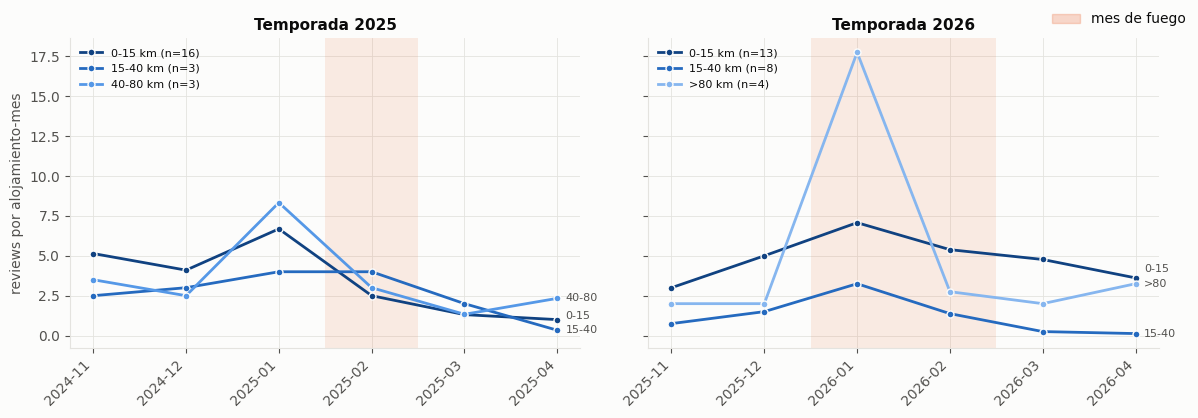

In [4]:
FUEGO_MESES = {"2025": ["2025-02"], "2026": ["2026-01", "2026-02"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, temp in zip(axes, ["2025", "2026"]):
    p = panel[panel["temporada"] == temp]
    serie = p.groupby(["mes_estadia", "banda"], observed=True).agg(media=("n_reviews", "mean"),
                                                                     n=("aloj_id", "nunique")).reset_index()
    meses = sorted(p["mes_estadia"].unique())
    x = {m: i for i, m in enumerate(meses)}
    for m in FUEGO_MESES[temp]:
        ax.axvspan(x[m] - 0.5, x[m] + 0.5, color=FUEGO, alpha=0.12, linewidth=0)
    finales = []
    for b in BANDAS:
        s = serie[serie["banda"] == b]
        if s.empty:
            continue
        ax.plot([x[m] for m in s["mes_estadia"]], s["media"], color=AZUL[b], linewidth=2, marker="o",
                markersize=5, markeredgecolor=SURF, label=f"{b} km (n={s['n'].max()})")
        finales.append([s["media"].iloc[-1], b, x[s["mes_estadia"].iloc[-1]]])
    # etiquetas directas al final de cada línea, separadas para que no se pisen
    finales.sort()
    for i in range(1, len(finales)):
        finales[i][0] = max(finales[i][0], finales[i - 1][0] + 0.9)
    for yv, b, xv in finales:
        ax.annotate(b, (xv, yv), xytext=(6, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
    ax.set_xticks(range(len(meses)), meses, rotation=45, ha="right")
    ax.set_title(f"Temporada {temp}")
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("reviews por alojamiento-mes")
fig.legend([Patch(color=FUEGO, alpha=0.25)], ["mes de fuego"], loc="upper right")
fig.tight_layout()
plt.show()

In [5]:
# Tabla de la serie (vista accesible)
panel.pivot_table(index=["temporada", "mes_estadia"], columns="banda", values="n_reviews", aggfunc="mean",
                  observed=True).reindex(columns=[b for b in BANDAS if b in panel["banda"].unique()]).round(2)

banda                  0-15  15-40  40-80    >80
temporada mes_estadia                           
2025      2024-11      5.14   2.50   3.50    NaN
          2024-12      4.10   3.00   2.50    NaN
          2025-01      6.69   4.00   8.33    NaN
          2025-02      2.50   4.00   3.00    NaN
          2025-03      1.31   2.00   1.33    NaN
          2025-04      1.00   0.33   2.33    NaN
2026      2025-11      3.00   0.75    NaN   2.00
          2025-12      5.00   1.50    NaN   2.00
          2026-01      7.08   3.25    NaN  17.75
          2026-02      5.38   1.38    NaN   2.75
          2026-03      4.77   0.25    NaN   2.00
          2026-04      3.62   0.12    NaN   3.25

## 3. Precio y rating por localidad

`precio_ref` es la tarifa de **hoy** para 15–17/01/2027 (2 noches, 2 adultos, USD): sirve como tarifa de
referencia para el ROI, **nunca** como outcome del fuego. El rating excluye alojamientos sin reviews (rating 0).

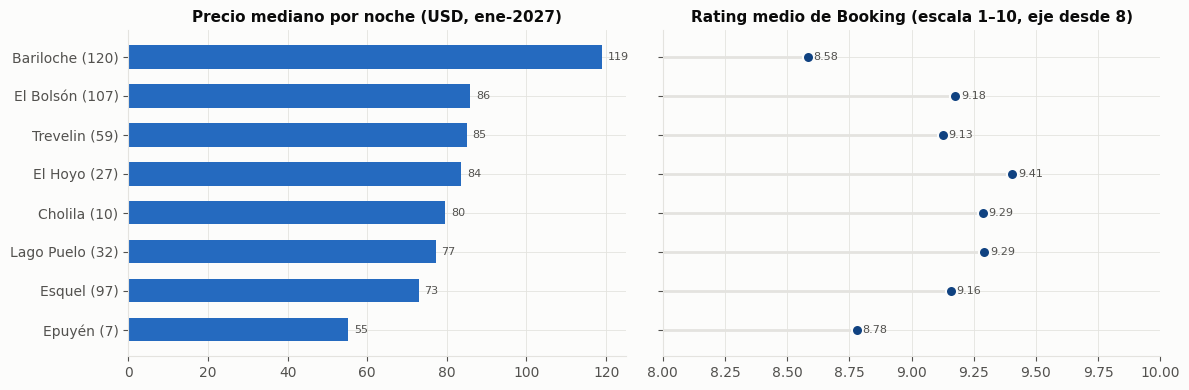

,alojamientos,precio_noche_mediana,rating_medio,reviews_totales
localidad,,,,
Epuyén,7,55.25,8.78,169
Esquel,97,73.00,9.16,4917
Lago Puelo,32,77.28,9.29,618
Cholila,10,79.64,9.29,97
El Hoyo,27,83.60,9.41,606
Trevelin,59,85.00,9.13,1265
El Bolsón,107,85.91,9.18,3746
Bariloche,120,119.00,8.58,39818


In [6]:
a = aloj.copy()
a["precio_noche_usd"] = a["precio_ref"] / 2
a.loc[a["n_reviews_total"].fillna(0) == 0, "rating"] = np.nan
tabla = a.groupby("localidad").agg(alojamientos=("aloj_id", "size"),
                                   precio_noche_mediana=("precio_noche_usd", "median"),
                                   rating_medio=("rating", "mean"),
                                   reviews_totales=("n_reviews_total", "sum")).sort_values("precio_noche_mediana")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
y = np.arange(len(tabla))
axes[0].barh(y, tabla["precio_noche_mediana"], height=0.6, color=AZUL["15-40"])
axes[0].set_yticks(y, [f"{l} ({n})" for l, n in zip(tabla.index, tabla["alojamientos"])])
axes[0].set_title("Precio mediano por noche (USD, ene-2027)")
for yi, v in zip(y, tabla["precio_noche_mediana"]):
    axes[0].annotate(f"{v:.0f}", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
axes[1].hlines(y, 8, tabla["rating_medio"], color=GRID, linewidth=2)
axes[1].scatter(tabla["rating_medio"], y, s=64, color=AZUL["0-15"], edgecolors=SURF, linewidths=1.5, zorder=3)
axes[1].set_xlim(8, 10)
axes[1].set_title("Rating medio de Booking (escala 1–10, eje desde 8)")
for yi, v in zip(y, tabla["rating_medio"]):
    axes[1].annotate(f"{v:.2f}", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
fig.tight_layout()
plt.show()
tabla.round(2)

In [7]:
# Precio y rating por localidad y tipo (para la tabla del dashboard)
a.pivot_table(index="localidad", columns="tipo", values="precio_noche_usd", aggfunc="median").round(0) \
 .loc[:, lambda d: d.notna().sum() >= 3]

tipo,aparthotel,apartment,bed_and_breakfast,camping,chalet,country_house,guest_house,holiday_home,homestay,hostel,hotel,inn,lodge,villa
localidad,,,,,,,,,,,,,,
Bariloche,NaN,117.0,169.0,NaN,NaN,NaN,61.0,105.0,97.0,99.0,135.0,100.0,NaN,NaN
Cholila,NaN,71.0,50.0,NaN,149.0,NaN,NaN,66.0,NaN,40.0,NaN,NaN,268.0,NaN
El Bolsón,NaN,87.0,45.0,28.0,92.0,114.0,50.0,106.0,35.0,29.0,157.0,93.0,79.0,1198.0
El Hoyo,75.0,82.0,NaN,40.0,97.0,73.0,44.0,73.0,NaN,NaN,NaN,85.0,130.0,NaN
Epuyén,NaN,55.0,NaN,NaN,114.0,NaN,44.0,50.0,NaN,NaN,NaN,64.0,NaN,NaN
Esquel,90.0,72.0,21.0,NaN,72.0,NaN,52.0,85.0,NaN,30.0,98.0,154.0,178.0,173.0
Lago Puelo,46.0,78.0,115.0,19.0,79.0,NaN,70.0,82.0,NaN,62.0,100.0,41.0,100.0,154.0
Trevelin,NaN,65.0,NaN,120.0,88.0,85.0,NaN,94.0,80.0,45.0,67.0,164.0,85.0,195.0


## 4. Primer número: DiD 2×2 (baseline)

β = (cerca durante − cerca antes) − (lejos durante − lejos antes), por alojamiento, con IC95% por bootstrap
clusterizado por alojamiento. Cerca = ≤15 km del foco más cercano de la temporada. Sin alojamientos truncados.

In [8]:
did.round(3)

,outcome,temporada,beta,ic95_lo,ic95_hi,pct_contrafactual,n_cerca,n_lejos
0,n_reviews,2025,-1.247,-4.392,2.331,-0.333,16,6
1,n_reviews,2026,-1.311,-7.082,2.968,-0.174,13,12
2,n_reviews,apilado,-2.279,-4.718,-0.117,-0.353,29,18
3,nota_media,2025,-1.128,-2.248,-0.095,-0.113,13,5
4,nota_media,2026,-0.337,-1.140,0.313,-0.036,12,11
5,nota_media,apilado,-0.581,-1.236,0.014,-0.061,25,16


**Lectura (MVP):** el volumen de reviews de los alojamientos cerca del fuego cae respecto de los lejanos
(β apilado ≈ −2,3 reviews por alojamiento-mes, −35% contra el contrafactual), con un IC que apenas excluye el 0.
La nota también baja, pero el IC apilado toca el 0. Con 47 alojamientos y pocos "lejos" en 2025, es un primer número,
no un resultado: el modelo con efectos fijos (`fepois`) y el event study del Producto 2 son los que cuentan.